### Feature Selection (отбор признаков) — это процесс выбора наиболее информативных признаков из набора данных для построения модели машинного обучения. Он помогает убрать ненужные, избыточные или малоинформативные признаки, что улучшает качество модели и делает ее более интерпретируемой.
Почему это важно:

Ускорится обучение модели.
Снизится переобучение (overfitting).
Повысится точность модели.
Облегчится интерпретация результатов.
Методы отбора признаков принято делить на несколько категорий:

Методы фильтрации (filter methods) — основаны на статистических тестах и независимы от алгоритма обучения.
Например, корреляционный анализ, Chi-square тест, ANOVA и пр.
Оберточные методы (wrapper methods) — используют модель для оценки качества подмножества признаков.
Например, RFE (Recursive Feature Elimination) и Sequential Feature Selection (SFS).
Встроенные методы (embedded methods) — выполняют отбор признаков в процессе обучения модели.
Например, L1-регуляризация и L2-регуляризация, а также Random Forest feature importance.
Методы фильтрации (filter methods)
Методы фильтрации основанны на теории вероятностей и статистических подходах. Наиболее популярными в этой группе методов считаются:

IG-индексирование (вычисление information gain);
хи-квадрат (chi-square);
корреляционный анализ.
Они позволяют ранжировать признаки по значимости, оценив степень корреляции каждого из них с целевой переменной. Далее модель машинного обучения использует только те предикторы, которые соответствуют определенным критериям.

Методы фильтрации хороши тем, что они достаточно быстро работают: у них низкая стоимость вычислений, которая зависит линейно от общего количества предикторов. Однако, они рассматривают каждый признак изолированно, не учитывая их взаимное влияние друг на друга в частности и на целевую переменную вообще. Поэтому точность моделирования с этими методами отбора признаков недостаточно высока.
Прирост информации (Information Gain, IG)
Вычисляет уменьшение энтропии в результате преобразования набора данных. Его можно использовать для отбора признаков путем оценки информационного прироста каждой переменной в контексте целевой переменной.

Прирост информации — это снижение энтропии за счет преобразования набора данных. Прирост информации рассчитывается путем сравнения энтропии набора данных до и после преобразования.
Information Gain рассчитывается по формуле:

$IG(Y|X) = H(X)-H(Y|X)$

IG — это мера того, насколько более упорядоченной становится для нас переменная Y, если мы знаем значения X. Или, говоря проще, существует ли корреляция между значениями X и Y, и насколько она велика.

Чем больше параметр IG — тем сильнее корреляция. Таким образом, мы легко можем вычислить information gain для всех признаков и выкинуть те, которые слабо влияют на целевую переменную.
Для начала посмотрим простую матрицу корреляции на данных про потребление электричества:

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@Классическое_МО_M6_img3.png)

Можно сразу заменить, что многие признаки имеют низкую линейную зависимость (корреляцию) с целевой переменной. Но зато тригонометрические признаки в целом имеют выше зависимость с целевой, чем обычные признаки, так как учитывают цикличность в данных.

Попробуем сравнить признаки и целевую переменную на нелинейные связи:

In [4]:
'''import opendatasets as od'''
import pandas as pd

'''od.download("https://www.kaggle.com/competitions/electricity-consumption")'''
df = pd.read_csv(r"C:\IDE\2 семестр\Классическое МО\Модуль 6. Оптимизация и настройка моделей\my_data_to_FS.csv")

c:\Users\troyd\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\feature_selection\_mutual_info.py:570: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)


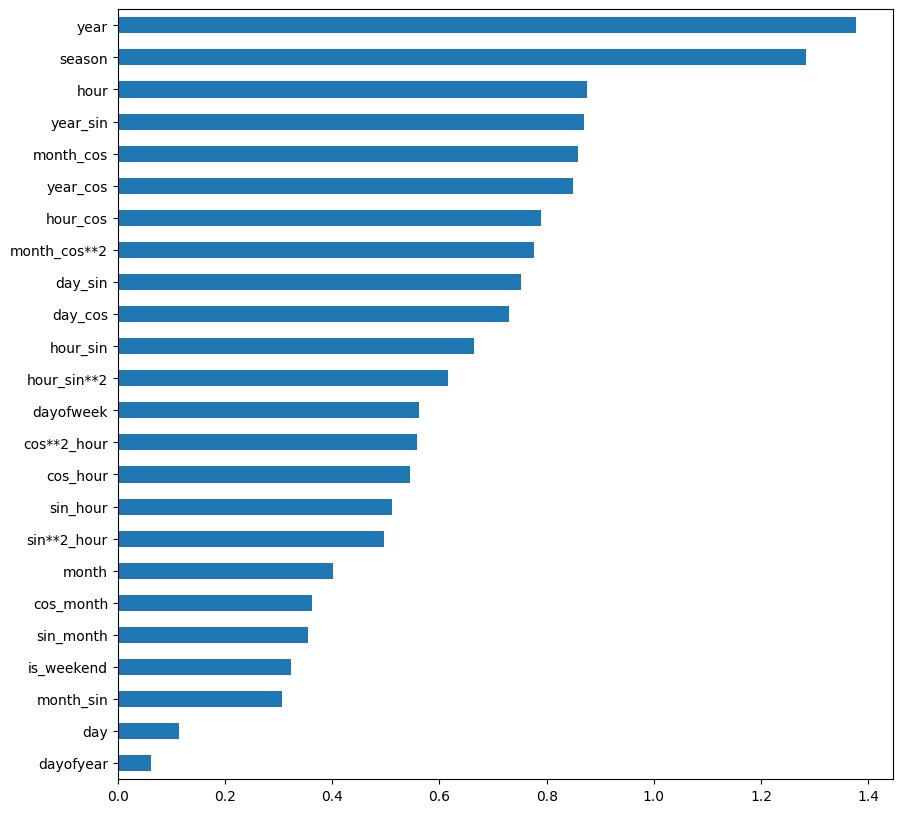

In [5]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import mutual_info_classif
import matplotlib.pyplot as plt

X = df.drop(columns=['total'])
y = df['total']

importances = mutual_info_classif(X, y)

feature_importances = pd.Series(importances, X.columns[0:len(X.columns)])
feature_importances = feature_importances.sort_values()

plt.figure(figsize=(10,10))
feature_importances.plot(kind='barh')
plt.show()

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@Классическое_МО_M6_img4.png)

mutual_info_classif — это функция из библиотеки sklearn подмодуля feature_selection, которая вычисляет взаимную информацию между признаками и целевой переменной. Она помогает понять, насколько информация одного признака уменьшает неопределенность относительно целевой переменной.

Взаимная информация показывает нелинейные зависимости, что делает ее более сильным инструментом, чем, например, простая корреляция.
Теперь, используя, эту информацию, можем оставить K лучших признаков для дальнейшего решения:

In [6]:
# Применение в отборе признаков:
# Функция особенно полезна в методах фильтрации:

from sklearn.feature_selection import SelectKBest

# Оставим только 5 лучших признака
selector = SelectKBest(mutual_info_classif, k=5)

X_selected = selector.fit_transform(X, y)

X_selected

c:\Users\troyd\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\feature_selection\_mutual_info.py:570: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)


array([[2.00500000e+03, 1.00000000e+00, 1.00000000e+00, 7.16782317e-04,
        9.99999743e-01],
       [2.00500000e+03, 1.00000000e+00, 1.00000000e+00, 1.43356427e-03,
        9.99998972e-01],
       [2.00500000e+03, 1.00000000e+00, 1.00000000e+00, 2.15034548e-03,
        9.99997688e-01],
       ...,
       [2.00800000e+03, 4.00000000e+00, 1.00000000e+00, 1.50518615e-02,
        9.99886714e-01],
       [2.00800000e+03, 4.00000000e+00, 1.00000000e+00, 1.57685588e-02,
        9.99875669e-01],
       [2.00800000e+03, 4.00000000e+00, 1.00000000e+00, 1.64852479e-02,
        9.99864109e-01]], shape=(34946, 5))

### Критерий хи-квадрат (Chi-square Test)
Используется для категориальных признаков в датасете. Мы вычисляем хи-квадрат между каждым признаком и целью, после выбираем желаемое количество признаков с лучшими показателями. Хи-квадрат проверяет, есть ли значимая разница между наблюдаемой и ожидаемой частотами двух категориальных переменных. Таким образом, проверяется нулевая гипотеза об отсутствии связи между двумя переменными.

Чтобы правильно применить критерий для проверки связи между различными функциями в наборе данных и целевой переменной, должны быть выполнены следующие условия:

категориальные переменные, которые выбираются независимо;
частота значений > 5.
Стоит отметить, что этот тип тестов требует неотрицательных и правильно масштабированных признаков.

Когда две функции независимы, наблюдаемое количество близко к ожидаемому количеству, поэтому у нас будет меньшее значение хи-квадрата. Столь высокое значение хи-квадрат указывает на то, что гипотеза о независимости неверна. Чем выше значение хи-квадрат, тем функция больше зависит от ответа, и ее можно выбрать для обучения модели.

$\chi_c^2 = \sum_{i=1}^{n} \frac{(O_i - E_i)^2}{E_i}$

### Критерий Фишера (F-тест)
Критерий Фишера — это один из наиболее широко используемых методов контролируемого выбора признаков.
Алгоритм, который мы будем использовать, возвращает ранги переменных на основе оценки критерия в порядке убывания, после чего уже следует их отбор.

In [7]:
import pandas as pd
import numpy as np
from skfeature.function.similarity_based import fisher_score
import matplotlib.pyplot as plt

# Вычисляем критерий
# Где X, y - входные и выходные данные соответственно.
ranks = fisher_score.fisher_score(X.to_numpy(), y.to_numpy())

# Делаем график наших "фич"
# Где data - ваш датасет
feature_importances = pd.Series(ranks, X.columns[0:len(X.columns)])
feature_importances = feature_importances.sort_values()

plt.figure(figsize=(10,10))
feature_importances.plot(kind='barh', color='teal')
plt.show()

ModuleNotFoundError: No module named 'skfeature'

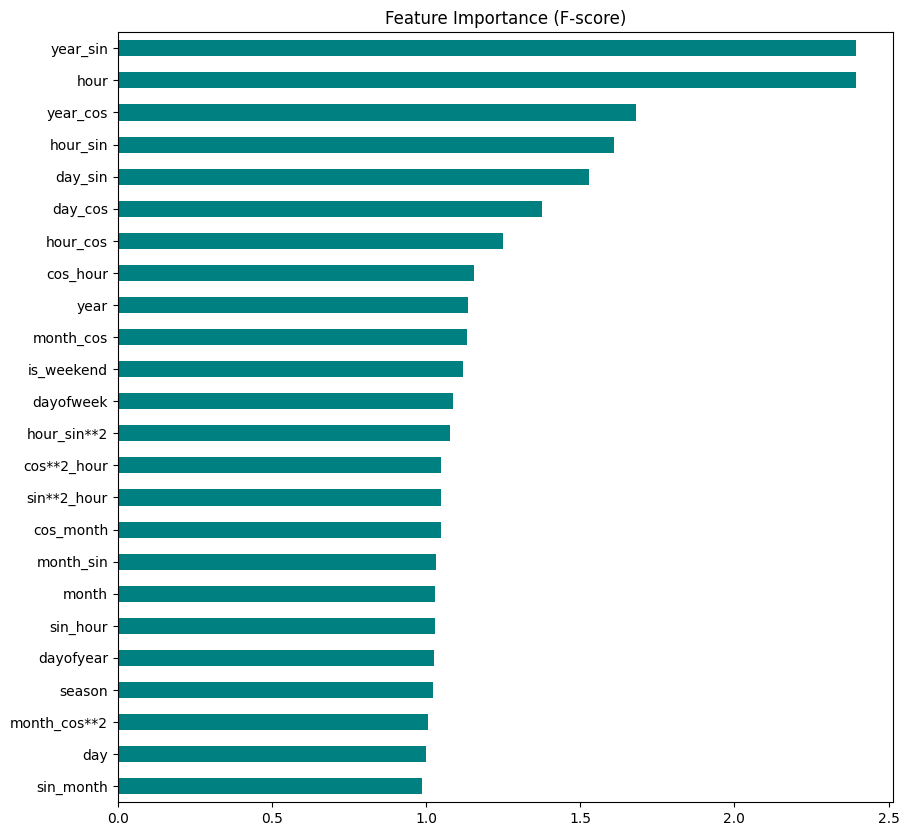

In [8]:
from sklearn.feature_selection import f_classif
import pandas as pd
import matplotlib.pyplot as plt

# Вычисляем F-статистику (аналог Fisher Score)
# f_classif вернет (scores, p_values)
scores, _ = f_classif(X, y)

# Создаем Series для графика
feature_importances = pd.Series(scores, index=X.columns)
feature_importances = feature_importances.sort_values()

# Визуализация
plt.figure(figsize=(10, 10))
feature_importances.plot(kind='barh', color='teal')
plt.title('Feature Importance (F-score)')
plt.show()

### Оберточные методы (wrapper methods)
Оберточные методы (Wrapper Methods) — это подход к выбору признаков, при котором мы строим модели и оцениваем их качество, чтобы решить, какие признаки оставить. Эти методы буквально «оборачивают» модель и проверяют ее производительность на разных наборах признаков.
В этой категории есть два подхода:

включение (forward selection);
исключение (backwards selection) предикторов.
Методы включения начинают с пустого подмножества, куда постепенно добавляются разные признаки. В случае исключения метод стартует с исходного множества признаков, постепенно удаляя из него переменные и пересчитывая классификатор. Далее выбирается подмножество признаков с наилучшими параметрами на обучающей выборке и тестируется на контрольном (тестовом) датасете. Есть много способов перебора предикторов: рекурсивное удаление и добавление, генетические алгоритмы, имитация отжига и т.д.. Оберточные методы отслеживают взаимосвязи между признаками, однако они требуют большего количества времени, чем фильтрация.

Существуют разные стратегии отбора:

Forward Selection (пошаговое добавление).
Начинаем с пустого набора признаков. По очереди добавляем признаки, которые наибольшим образом улучшают метрику модели. Продолжаем, пока улучшение не станет незначительным.
Backward Elimination (пошаговое удаление).
Начинаем со всех признаков. По очереди убираем наименее значимые признаки (те, что меньше всего влияют на метрику). Продолжаем, пока метрика не начнет резко ухудшаться.
Recursive Feature Elimination (RFE).
Строим модель на полном наборе признаков. Удаляем наименее важный признак (по важности или коэффициентам модели). Повторяем процесс до нужного количества признаков.
Пример реализации с использованием библиотеки sklearn
Класс SequentialFeatureSelectorв Scikit-learn поддерживает как прямой, так и обратный выбор. Класс SequentialFeatureSelector в scikit-learn работает путем итеративного добавления или удаления признаков из набора данных для улучшения производительности предиктивной модели.

Конструктор алгоритма:

In [9]:
'''sklearn.feature_selection.SequentialFeatureSelector(estimator, *, n_features_to_select=None, direction='forward', scoring=None, cv=5, n_jobs=None)'''
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression

X = df.drop(columns=['total'])
y = df['total']

clf = LinearRegression()

sfs = SequentialFeatureSelector(clf, n_features_to_select = 5)

sfs.fit(X, y)
'''Далее с помощью атрибутов алгоритма, можем посмотреть какие признаки отобрал алгоритм:'''

sfs.support_
'''array([ True, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False,  True, False,  True,
       False, False, False, False,  True,  True])
Видим, что из 24 признаков алгоритм отобрал 5 лучших признаков с индексами: 0, 15, 17, 22, 23. Посмотрим названия этих признаков:'''

pd.DataFrame(sfs.support_, index=X.columns, columns=["Rank"])
'''Далее мы можем обучить наш алгоритм заново только на отобранных признаках.'''

'Далее мы можем обучить наш алгоритм заново только на отобранных признаках.'

Рекурсивное исключение признаков
Первым элементом, необходимым для рекурсивного исключения признаков (recursive feature elimination), является оценщик — например, линейная модель или дерево решений.

У таких моделей есть коэффициенты для линейных моделей и важности признаков в деревьях решений. Для выбора оптимального количества признаков нужно обучить оценщика и выбрать признаки с помощью коэффициентов или значений признаков. Наименее важные признаки будут удаляться. Этот процесс будет повторяться рекурсивно о тех пор, пока не будет получено оптимальное число признаков.

sklearn.feature_selection.RFE(estimator, *, n_features_to_select=None, step=1, verbose=0, importance_getter='auto')
estimator — оценщик машинного обучения, который может выдать важность признаков за счет атрибутов coef_ или feature_importances attributes.
n_features_to_select — количество признаков для выбора. Отбирает половину по умолчанию.
step — целое число, которое указывает количество признаков, которые будут удалены на каждой итерации. Или же оно дает число в диапазоне от 0 до 1, указывающее процент признаков, подлежащих удалению на каждой итерации.
from sklearn.feature_selection import RFE
import numpy as np

clf = LinearRegression()

rfe = RFE(clf, n_features_to_select=6)
rfe.fit(X, y)
Посмотрим, какие признаки отобрал рекурсивный алгоритм:

rfe.support_
array([False, False, False, False,  True, False, False, False, False,
       False, False, False, False, False,  True,  True, False, False,
       False, False,  True, False,  True,  True])
Видим, что из 24 признаков алгоритм отобрал 6 лучших признаков с индексами: 4, 14, 15, 20, 22, 23. Далее можем обучить алгоритм заново только на отобранных признаках.

Встроенные методы (embedded methods)
Встроенные методы (embedded methods) не разделяют отбор признаков и обучение классификатора, а выделяют предикторы во время процесса расчета модели. Эти алгоритмы требуют меньше вычислений, чем оберточные методы, но больше, чем фильтрация.
Основным методом этой категории является регуляризация — добавление дополнительных ограничений (штрафов) к условиям задачи, чтобы построить алгоритм, минимизирующий ошибку и количество используемых переменных.

При этом выделяют два подхода:

L1 (лассо, lasso regression, регуляризация через манхэттенское расстояние).
L2 (регуляризация Тихонова или ридж-регрессия, ridge regression).
Регуляризация позволяет выявить взаимовлияние переменных, но занимает больше времени, чем методы фильтрации.
Регуляризация LASSO (L1)
Лассо штрафует весовые коэффициенты модели для изменения их важности для модели и может даже обнулить их (то есть убрать эти переменные из конечной модели).
Обычно Лассо используется, если набор данных содержит большое число переменных и требуется исключить некоторые из них, чтобы лучше понять, как важные признаки влияют на модель (то есть те признаки, которые были выбраны Лассо и у которых установлена важность).

L2 Регуляризация методом Ridge
Задачей Ridge является сохранение всех переменных и в то же время присвоение им важности на основе вклада в эффективность модели. Ridge будет хорошим выбором, если набор данных содержит небольшое число переменных и все они необходимы для интерпретации выводов и полученных результатов.

Так как Ridge оставляет все переменные, а Лассо лучше устанавливает их важность, был разработан алгоритм, объединяющий лучшие особенности обеих регуляризаций и известный как Elastic-Net.